In [4]:
import pandas as pd
df = pd.read_csv('vancouver_graphcast_aligned_2020.csv',index_col=0, parse_dates=True)

In [5]:
print(df.shape)
print(df.index.dtype)
df.head()

(732, 5)
datetime64[us]


,ERA5_obs,GraphCast_1day,GraphCast_3day,GraphCast_5day,GraphCast_7day
valid_time,,,,,
2020-01-01 00:00:00,1.008802,2.203431,1.281958,1.177884,1.455614
2020-01-01 12:00:00,1.196059,1.298054,0.801821,-0.615437,-0.529792
2020-01-02 00:00:00,1.686390,1.561596,1.605364,0.863070,0.671142
2020-01-02 12:00:00,-4.341987,-3.845903,-4.354504,-2.230509,-1.698909
2020-01-03 00:00:00,-3.014572,-3.304272,-3.238037,-1.763912,-1.173375


In [6]:
df.columns

Index(['ERA5_obs', 'GraphCast_1day', 'GraphCast_3day', 'GraphCast_5day',
       'GraphCast_7day'],
      dtype='str')

In [9]:
df['GraphCast_1day']-df['ERA5_obs']

valid_time
2020-01-01 00:00:00    1.194629
2020-01-01 12:00:00    0.101996
2020-01-02 00:00:00   -0.124794
2020-01-02 12:00:00    0.496084
2020-01-03 00:00:00   -0.289700
                         ...   
2020-12-29 12:00:00   -0.447236
2020-12-30 00:00:00   -0.693478
2020-12-30 12:00:00    0.086149
2020-12-31 00:00:00    1.098672
2020-12-31 12:00:00    0.565339
Length: 732, dtype: float64

In [11]:
err_1 = df['GraphCast_1day']-df['ERA5_obs']
err_1.head(3)

valid_time
2020-01-01 00:00:00    1.194629
2020-01-01 12:00:00    0.101996
2020-01-02 00:00:00   -0.124794
dtype: float64

In [13]:
print('bias',err_1.mean())
print('MAE',err_1.abs().mean())
print('RMSE',(err_1 ** 2).mean() ** 0.5)

bias 0.015729212614559136
MAE 0.4515201977823823
RMSE 0.6088512215218529


In [15]:
leads = [1,3,5,7]
rows = []
for d in leads:
    err = df[f'GraphCast_{d}day']-df['ERA5_obs']
    rows.append({'lead_days':d, 'MAE': err.abs().mean(), 'RMSE':(err ** 2).mean() ** 0.5, 'bias': err.mean()})
metrics = pd.DataFrame(rows).set_index('lead_days')
metrics

,MAE,RMSE,bias
lead_days,,,
1,0.451520,0.608851,0.015729
3,0.667749,0.895589,-0.085046
5,1.087357,1.472710,-0.193470
7,1.720429,2.451499,-0.314837


In [16]:
import numpy as np

In [34]:
x = metrics.index.values
y = metrics['MAE'].values

slope, intercept = np.polyfit(x,y,1)
print('slope',slope)

slope 0.21131668004976503


In [35]:
print(x,y,slope,intercept)

[1 3 5 7] [0.4515202  0.66774947 1.08735703 1.72042888] 0.21131668004976503 0.13649717231996522


In [36]:
import matplotlib.pyplot as plt

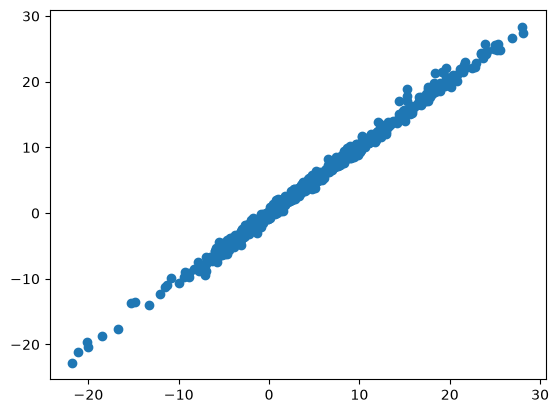

In [32]:
fig, ax = plt.subplots()
ax.scatter(df['ERA5_obs'],df['GraphCast_1day'])
plt.show()

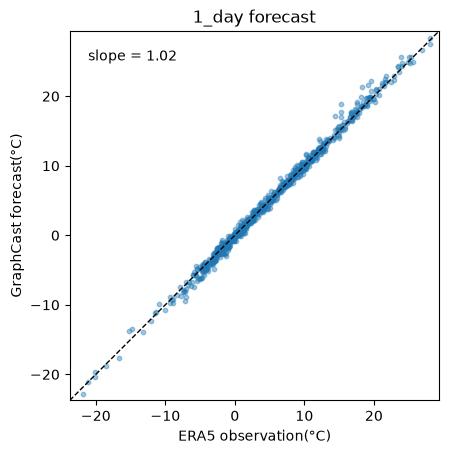

In [41]:
obs = df['ERA5_obs']
fc = df['GraphCast_1day']
low = min(obs.min(), fc.min()) - 1
high = max(obs.max(), fc.max()) + 1

fig, ax = plt.subplots()
ax.scatter(obs, fc, s=10, alpha=0.4)
ax.plot([low,high],[low,high],'k--', linewidth=1)
ax.set_xlim(low,high)
ax.set_ylim(low,high)
ax.set_aspect('equal')
ax.set_xlabel('ERA5 observation(°C)')
ax.set_ylabel('GraphCast forecast(°C)')
ax.set_title('1_day forecast')
fit_slope = np.polyfit(obs, fc, 1)[0]
ax.text(0.05, 0.92, f'slope = {fit_slope:.2f}', transform = ax.transAxes)
fig.savefig('main_question_1day.png', dpi=300, bbox_inches = 'tight')
plt.show()

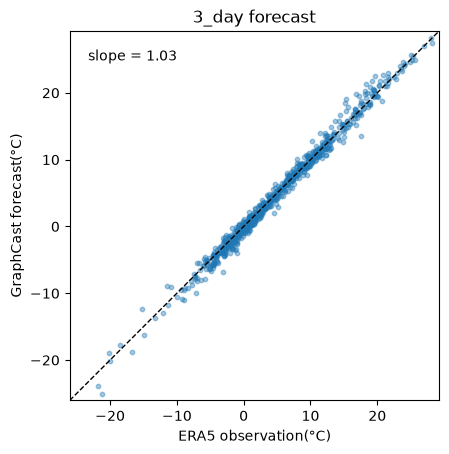

In [42]:
obs = df['ERA5_obs']
fc = df['GraphCast_3day']
low = min(obs.min(), fc.min()) - 1
high = max(obs.max(), fc.max()) + 1

fig, ax = plt.subplots()
ax.scatter(obs, fc, s=10, alpha=0.4)
ax.plot([low,high],[low,high],'k--', linewidth=1)
ax.set_xlim(low,high)
ax.set_ylim(low,high)
ax.set_aspect('equal')
ax.set_xlabel('ERA5 observation(°C)')
ax.set_ylabel('GraphCast forecast(°C)')
ax.set_title('3_day forecast')
fit_slope = np.polyfit(obs, fc, 1)[0]
ax.text(0.05, 0.92, f'slope = {fit_slope:.2f}', transform = ax.transAxes)
fig.savefig('main_question_3day.png', dpi=300, bbox_inches = 'tight')
plt.show()

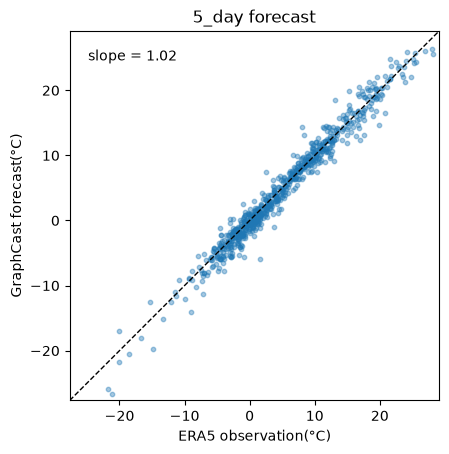

In [43]:
obs = df['ERA5_obs']
fc = df['GraphCast_5day']
low = min(obs.min(), fc.min()) - 1
high = max(obs.max(), fc.max()) + 1

fig, ax = plt.subplots()
ax.scatter(obs, fc, s=10, alpha=0.4)
ax.plot([low,high],[low,high],'k--', linewidth=1)
ax.set_xlim(low,high)
ax.set_ylim(low,high)
ax.set_aspect('equal')
ax.set_xlabel('ERA5 observation(°C)')
ax.set_ylabel('GraphCast forecast(°C)')
ax.set_title('5_day forecast')
fit_slope = np.polyfit(obs, fc, 1)[0]
ax.text(0.05, 0.92, f'slope = {fit_slope:.2f}', transform = ax.transAxes)
fig.savefig('main_question_5day.png', dpi=300, bbox_inches = 'tight')
plt.show()

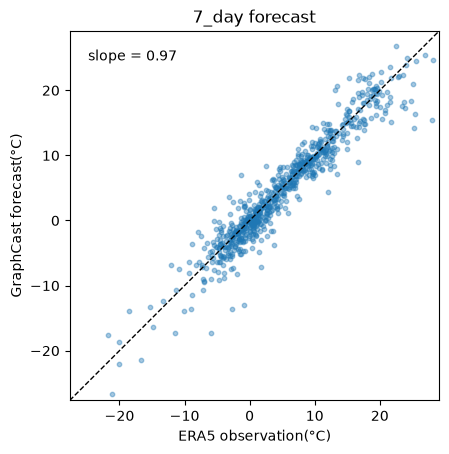

In [44]:
obs = df['ERA5_obs']
fc = df['GraphCast_7day']
low = min(obs.min(), fc.min()) - 1
high = max(obs.max(), fc.max()) + 1

fig, ax = plt.subplots()
ax.scatter(obs, fc, s=10, alpha=0.4)
ax.plot([low,high],[low,high],'k--', linewidth=1)
ax.set_xlim(low,high)
ax.set_ylim(low,high)
ax.set_aspect('equal')
ax.set_xlabel('ERA5 observation(°C)')
ax.set_ylabel('GraphCast forecast(°C)')
ax.set_title('7_day forecast')
fit_slope = np.polyfit(obs, fc, 1)[0]
ax.text(0.05, 0.92, f'slope = {fit_slope:.2f}', transform = ax.transAxes)
fig.savefig('main_question_7day.png', dpi=300, bbox_inches = 'tight')
plt.show()

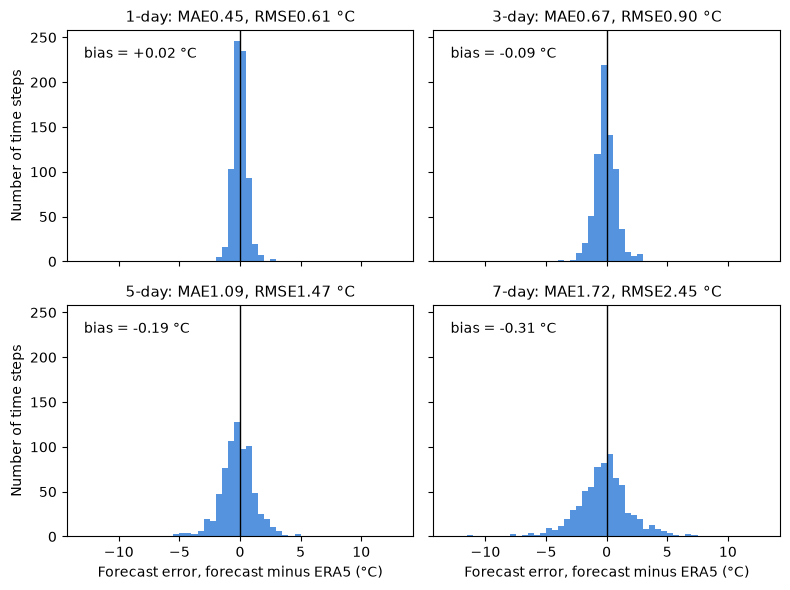

In [47]:
leads = [1,3,5,7]
lim = 0
for d in leads:
    lim = max(lim, (df[f'GraphCast_{d}day']-df['ERA5_obs']).abs().max())
lim = np.ceil(lim)
bins = np.arange(-lim, lim + 0.5, 0.5)

fig, axes = plt.subplots(2,2, figsize=(8,6),sharex=True,sharey=True)
for ax, d in zip(axes.flat, leads):
    e = df[f'GraphCast_{d}day'] - df[f'ERA5_obs']
    ax.hist(e, bins=bins, color='#2a78d6',alpha=0.8)
    ax.axvline(0,color='black', linewidth=1)
    mae = metrics.loc[d, 'MAE']
    rmse = metrics.loc[d, 'RMSE']
    bias = metrics.loc[d,'bias']
    ax.set_title(f'{d}-day: MAE{e.abs().mean():.2f}, RMSE{(e ** 2).mean() ** 0.5:.2f} °C', fontsize=11)
    ax.text(0.05, 0.88, f'bias = {bias:+.2f} °C', transform=ax.transAxes)

for ax in axes[1]:
    ax.set_xlabel('Forecast error, forecast minus ERA5 (°C)')
for ax in axes[:, 0]:
    ax.set_ylabel('Number of time steps')

fig.tight_layout()
fig.savefig('fig2_Sub_question.png', dpi=300, bbox_inches='tight')
plt.show()

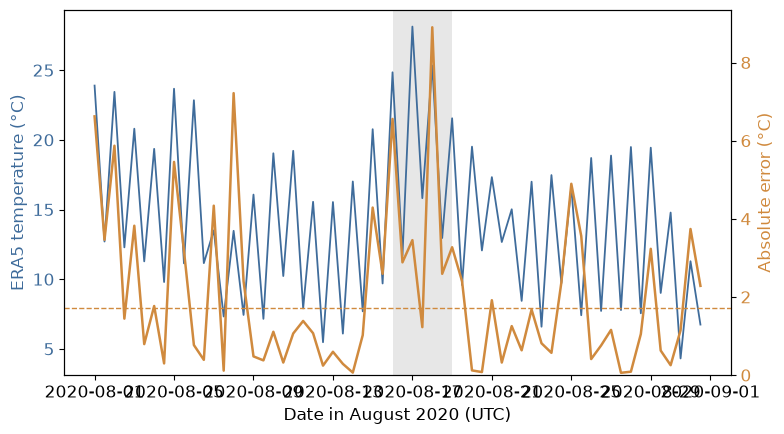

In [50]:
plt.rcParams.update({'font.size':12})
c_temp, c_err = '#3F6C9B', '#D08A3E'
aug = df.loc['2020-08']
abs_err7 = (df['GraphCast_7day'] - df['ERA5_obs']).abs()
aug_err = abs_err7.loc['2020-08']

fig, ax1 = plt.subplots(figsize=(8, 4.5))
line1, = ax1.plot(aug.index, aug['ERA5_obs'], color=c_temp, linewidth=1.3, label='ERA5 temperature (left axis)')
span = ax1.axvspan(pd.Timestamp('2020-08-16'), pd.Timestamp('2020-08-19'), color='#BDBDBD', alpha=0.35, linewidth=0, label='Event window')
ax1.set_xlabel('Date in August 2020 (UTC)')
ax1.set_ylabel('ERA5 temperature (°C)', color=c_temp)
ax1.tick_params(axis='y', labelcolor=c_temp)

ax2 = ax1.twinx()
line2, = ax2.plot(aug_err.index, aug_err, color=c_err, linewidth=1.8, label='7-day forecast abosolute error')
line3 = ax2.axhline(abs_err7.mean(), color=c_err, linestyle='--', linewidth=1, label='All year MAE 7-day')
ax2.set_ylabel('Absolute error (°C)', color=c_err)
ax2.tick_params(axis='y', labelcolor=c_err)
ax2.set_ylim(bottom=0)

fig.tight_layout()
fig.savefig('fig3_Sub_question.png', dpi=300, bbox_inches='tight')
plt.show()